# PREDICCIÓN COSTE ESPERADO DEL SEGURO

Con el objetivo de estimar, mediante un modelo predictivo, el coste esperado del seguro en
función de las variables que considerén oportunas, se procedera a crear diferentes tipos de modelos y se hará una comparación para determinar cual usar para dicho objetivo, nuestra variable objetivo (coste esperado) en este caso es la variable "Prima"


| Nombre                 | Definición                                                                                  |
|------------------------|---------------------------------------------------------------------------------------------|
| ID                     | Identificador único del préstamo.                                                           |
| Edad                   | Edad del prestatario.                                                                       |
| Ingresos               | Ingreso anual del prestatario.                                                              |
| Monto_Inicial          | Cantidad de dinero acordada.                                                                |
| Scoring_Crediticio     | Puntuación crediticia del prestatario que indica su solvencia.                              |
| Meses_Empleo           | Número de meses de vida laboral del prestatario.                                            |
| Num_Creditos           | Número de líneas de crédito abiertas del prestatario.                                       |
| Ratio_Interes          | Ratio de interés del préstamo (multiplicado por 100).                                       |
| Duracion               | Duración del préstamo en meses.                                                             |
| Ratio_Deuda_Ingresos   | Ratio de deuda frente a ingresos, que indica la deuda del prestatario en comparación con sus ingresos. |
| Estudios               | Nivel más alto de educación alcanzado por el prestatario.                                   |
| Tipo_Jornada_Laboral   | Tipo de jornada laboral del prestatario.                                                    |
| Estado_Civil           | Estado civil del prestatario.                                                               |
| Posesion_Hipoteca      | Indicador de si el prestatario posee una hipoteca.                                          |
| Personas_Cargo         | Número de personas a cargo del prestatario.                                                 |
| Proposito              | Propósito para el cual se solicita el préstamo.                                             |
| Fiador                 | Indicador de si el prestatario dispone de cofirmante o fiador.                              |
| Impago                 | Variable objetivo binaria que indica si el préstamo entró en mora (1) o no (0).            |
| Prima                  | Prima de la póliza de protección de pagos.                                                  |

## REGRESIÓN LINEAL MULTIPLE

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

Reutilizamos un dataframe, el cual se ha utilizado para cumplir el objetivo Nº2, ya que nos servira para nuestro modelo predictivo, tenemos los resultados de las probabilidades de pago e impago y transformadas ya a numericas posibles variables a utilizar en este modelo que en un primer momento eran strings

In [2]:
CARPETA = "data"
FICHERO = "df_prob.csv"
df = pd.read_csv(os.path.join(CARPETA, FICHERO))

df.head()

,ID,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,...,Prima,Estudios_Doctorado,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Tiempo parcial,prob_pago,prob_impago,prediccion
0,6B4H6E,22,16000.0,10000,769,22.0,1,8.96,48.0,0.32,...,65.85,0,0,0,0,1,0,0.392497,0.607503,1
1,VKTUXP,33,38308.0,16474,699,70.0,3,14.07,36.0,0.20,...,260.60,0,0,1,0,0,0,0.348994,0.651006,1
2,5P9OVL,51,51271.0,40770,812,309.0,1,12.66,12.0,0.36,...,221.02,0,1,0,0,0,0,0.659043,0.340957,0
3,YL0W8G,30,31923.0,36707,813,43.0,1,8.96,24.0,0.32,...,125.00,0,1,0,0,0,0,0.495953,0.504047,1
4,YP8WTV,28,27373.0,86981,765,60.0,2,10.07,48.0,0.55,...,800.00,0,0,0,0,0,0,0.433751,0.566249,1


## 1. Análisis exploratorio

Hacemos un análisis exploratorio para ver el tipo de datos que tenemos, si hay nulos, la media, la desviación estandar, la mediana y asi podremos saber como hacer un correcto uso de ellos para nuestro modelo predictivo

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101895 entries, 0 to 101894
Data columns (total 26 columns):
 #   Column                               Non-Null Count   Dtype  
---  ------                               --------------   -----  
 0   ID                                   101895 non-null  object 
 1   Edad                                 101895 non-null  int64  
 2   Ingresos                             101895 non-null  float64
 3   Monto_Inicial                        101895 non-null  int64  
 4   Scoring_Crediticio                   101895 non-null  int64  
 5   Meses_Empleo                         101895 non-null  float64
 6   Num_Creditos                         101895 non-null  int64  
 7   Ratio_Interes                        101895 non-null  float64
 8   Duracion                             101895 non-null  float64
 9   Ratio_Deuda_Ingresos                 101895 non-null  float64
 10  Estado_Civil                         101895 non-null  float64
 11  Posesion_Hipo

In [4]:
print("Valores ausentes por columna:")
print(df.isnull().sum().sort_values(ascending=False).head(10))

print("\nFilas duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["ID"].duplicated().sum())

print("\nDistribución de la prima:")
display(df["Prima"].describe())

print(
    "Porcentaje de primas iguales a 800:",
    round((df["Prima"] == 800).mean() * 100, 2),
    "%"
)

Valores ausentes por columna:
ID                      0
Edad                    0
Ingresos                0
Monto_Inicial           0
Scoring_Crediticio      0
Meses_Empleo            0
Num_Creditos            0
Ratio_Interes           0
Duracion                0
Ratio_Deuda_Ingresos    0
dtype: int64

Filas duplicadas: 0
IDs duplicados: 0

Distribución de la prima:


count    101895.000000
mean        384.706766
std         267.147571
min          10.000000
25%         137.465000
50%         336.270000
75%         610.695000
max         800.000000
Name: Prima, dtype: float64

Porcentaje de primas iguales a 800: 11.08 %


In [5]:
df.describe()

,Edad,Ingresos,Monto_Inicial,Scoring_Crediticio,Meses_Empleo,Num_Creditos,Ratio_Interes,Duracion,Ratio_Deuda_Ingresos,Estado_Civil,...,Prima,Estudios_Doctorado,Estudios_Grado Universitario,Estudios_Máster,Tipo_Jornada_Laboral_Autónomo,Tipo_Jornada_Laboral_Desempleado,Tipo_Jornada_Laboral_Tiempo parcial,prob_pago,prob_impago,prediccion
count,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,...,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000,101895.000000
mean,39.665666,41502.987271,45009.339889,692.304549,212.911409,1.998135,10.670103,37.251065,0.321381,1.115383,...,384.706766,0.079454,0.372138,0.159390,0.148506,0.099504,0.201924,0.542098,0.457902,0.400815
std,10.103095,16034.114815,46629.197358,87.517169,151.093061,0.998260,3.797959,14.155323,0.181193,0.689165,...,267.147571,0.270448,0.483377,0.366041,0.355602,0.299340,0.401437,0.159452,0.159452,0.490066
min,19.000000,16000.000000,3000.000000,398.000000,0.000000,1.000000,2.010000,12.000000,0.100000,0.000000,...,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.077652,0.064705,0.000000
25%,33.000000,30468.000000,14994.000000,636.000000,69.000000,1.000000,7.960000,24.000000,0.140000,1.000000,...,137.465000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.422543,0.335729,0.000000
50%,40.000000,39082.000000,40000.000000,704.000000,208.000000,2.000000,10.600000,36.000000,0.290000,1.000000,...,336.270000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.546253,0.453747,0.000000
75%,46.000000,50137.500000,47396.500000,761.000000,337.000000,3.000000,13.260000,48.000000,0.550000,2.000000,...,610.695000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.664271,0.577457,1.000000
max,64.000000,120000.000000,400000.000000,845.000000,628.000000,4.000000,24.440000,60.000000,0.550000,2.000000,...,800.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.935295,0.922348,1.000000


Observamos la distribución de la variable "Prima" que es la que queremos predecir

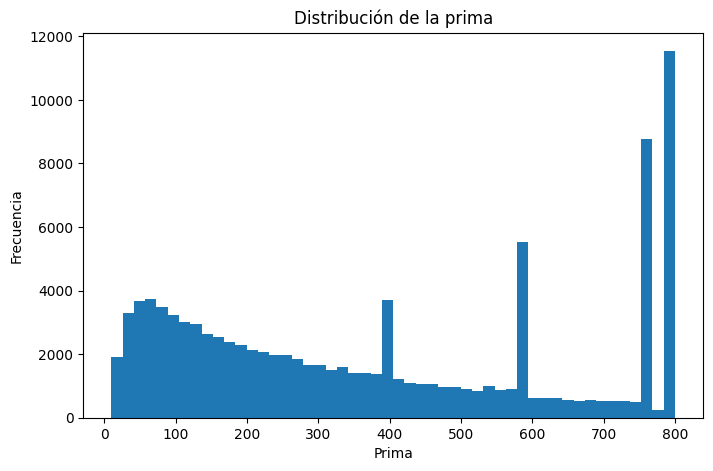

In [6]:
plt.figure(figsize=(8, 5))

plt.hist(df["Prima"], bins=50)

plt.xlabel("Prima")
plt.ylabel("Frecuencia")
plt.title("Distribución de la prima")

plt.show()

Observamos que la Prima está truncada en 800, es decir, las primas mayores a ese valor por lo que sea se quedan con el valor de 800, no existen valores más altos de ese valor en nuestro dataset, por lo que probamos a eliminarlas y continuaremos con el proceso si al eliminarlas no nos desacemos de la gran mayoria de nuestros datos.

PD: Hemos probado el modelo borrando todas las primas igual o mayores a 800 y tambien quedandonos con un porcentaje menor de Primas = 800, y en los dos casos el modelo rendia peor, asi que, hemos mantenido la idea principal y no vamos a borrar datos de la variable Y

In [7]:
#df = df[df["Prima"] <= 800]

In [8]:
#df = df.sample(frac=0.4, random_state=42)

Observamos que solo borrariamos un 11% de nuestro dataset por lo que decidimos continuar con el proceso

In [9]:
#n_filas = (df["Prima"] == 800).sum()
#print(f"Filas a borrar: {n_filas}")


#print(f"Porcentaje: {n_filas / len(df):.2%}")

In [10]:
print(f"Filas y columnas: {df.shape}")
print(f"\nColumnas: {df.columns.tolist()}")

Filas y columnas: (101895, 26)

Columnas: ['ID', 'Edad', 'Ingresos', 'Monto_Inicial', 'Scoring_Crediticio', 'Meses_Empleo', 'Num_Creditos', 'Ratio_Interes', 'Duracion', 'Ratio_Deuda_Ingresos', 'Estado_Civil', 'Posesion_Hipoteca', 'Personas_Cargo', 'Proposito', 'Fiador', 'Impago', 'Prima', 'Estudios_Doctorado', 'Estudios_Grado Universitario', 'Estudios_Máster', 'Tipo_Jornada_Laboral_Autónomo', 'Tipo_Jornada_Laboral_Desempleado', 'Tipo_Jornada_Laboral_Tiempo parcial', 'prob_pago', 'prob_impago', 'prediccion']


Creamos una matriz de correlación para ver que variables tienen relación con nuestra variable objetivo "Prima", con el fin de hacer una selección final para poder separar en X e Y, y obetener las variables que influiran en nuestro modelo.

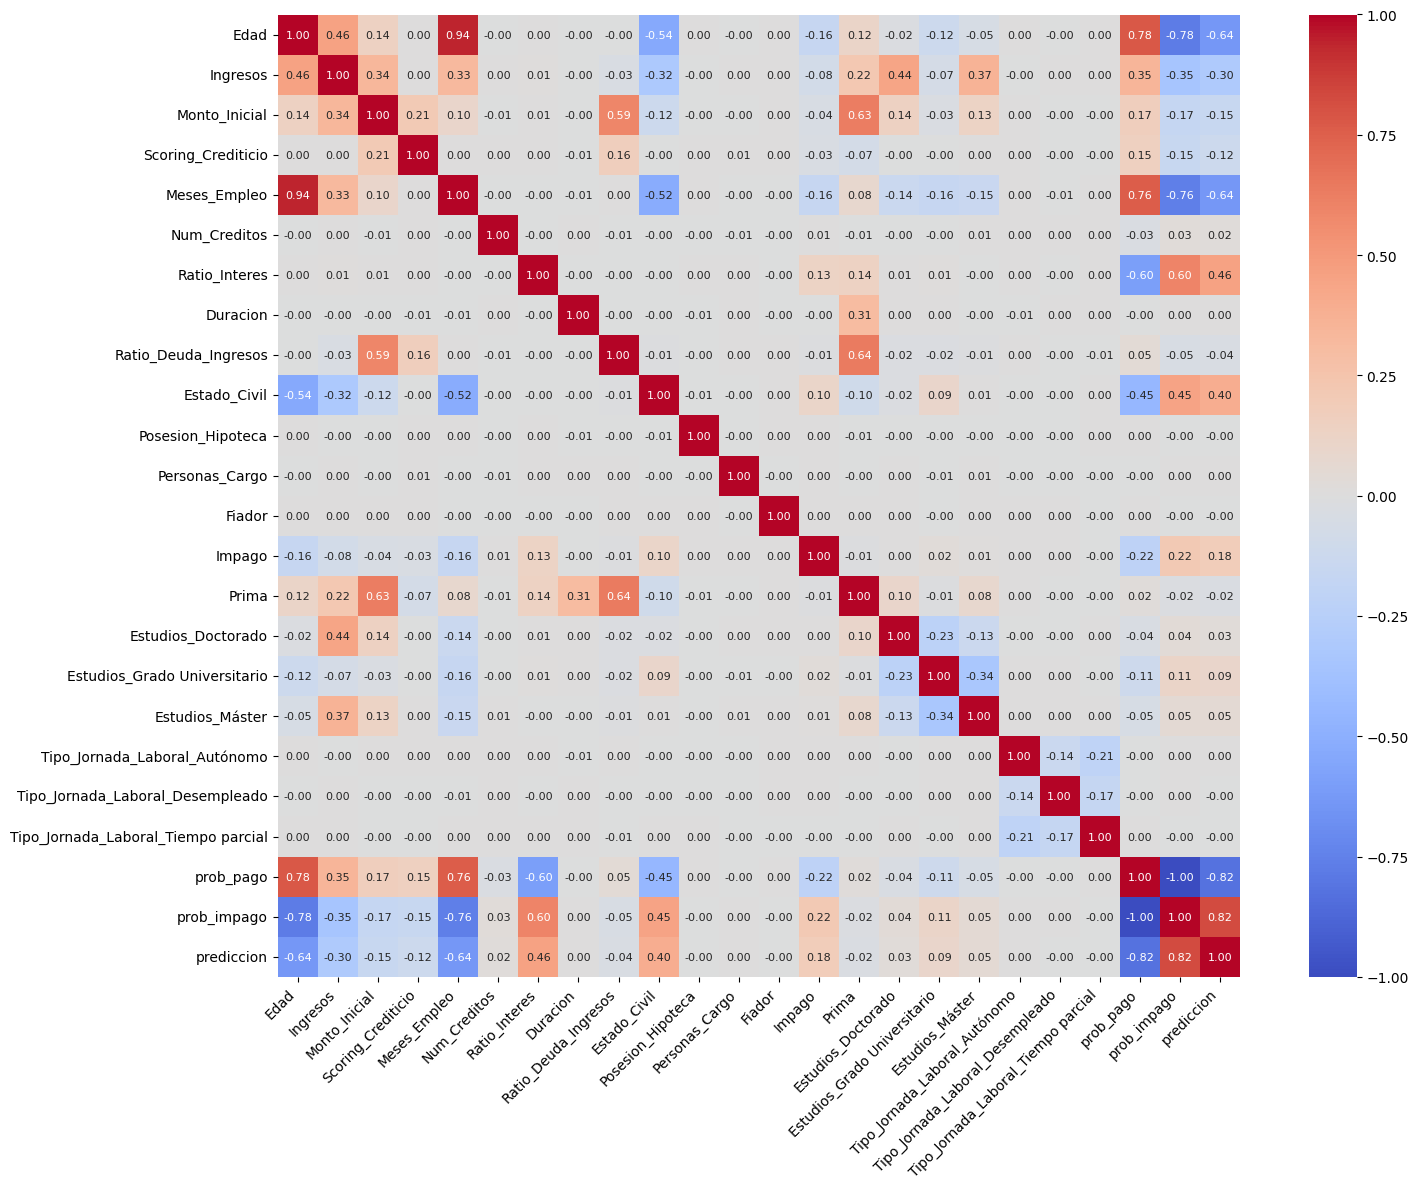

In [11]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(16,12))
sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    square=True,
    annot_kws={"size": 8}
)

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

Para una mejor visualización vamos a hacer un heatmap pero solo con la variable objetivo en nuestro caso la variable "Prima", con esto sera mucho más visibles cuales son las variables a elegir.

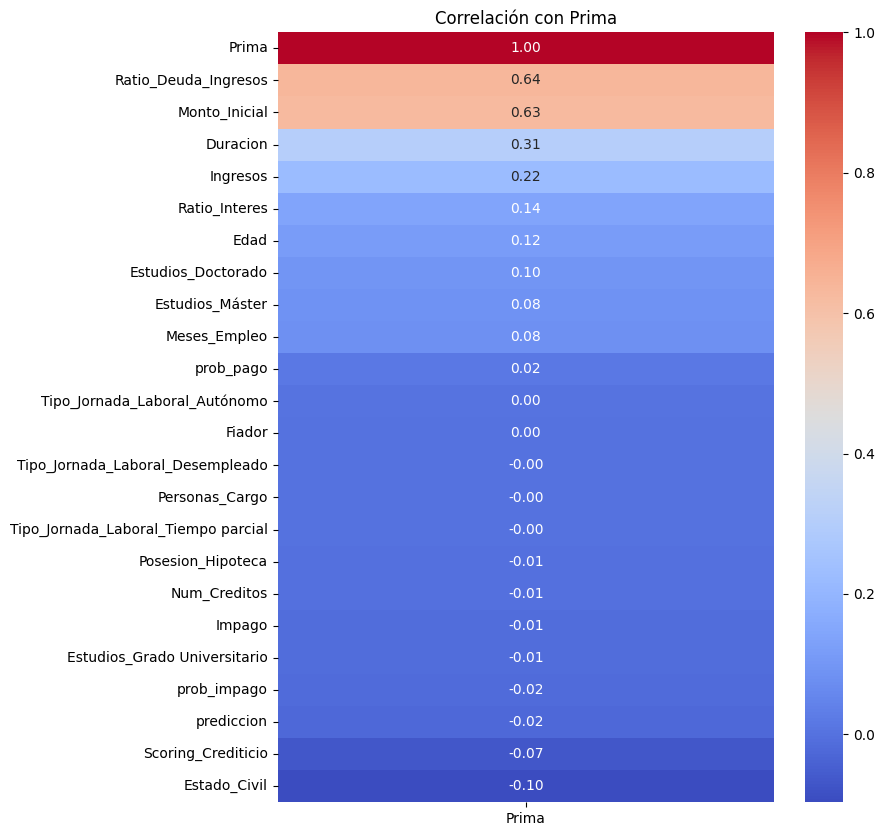

In [12]:
corr_prima = (
    df.corr(numeric_only=True)["Prima"]
    .sort_values(ascending=False)
)

plt.figure(figsize=(8,10))
sns.heatmap(
    corr_prima.to_frame(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlación con Prima")
plt.show()

Resultados númericos de las correlaciones con la variable objetivo

In [13]:
corr_prima = (
    df.corr(numeric_only=True)["Prima"]
    .drop("Prima")
    .abs()
    .sort_values(ascending=False)
)

print(corr_prima)

Ratio_Deuda_Ingresos                   0.636085
Monto_Inicial                          0.626538
Duracion                               0.305995
Ingresos                               0.222311
Ratio_Interes                          0.139729
Edad                                   0.115464
Estado_Civil                           0.096761
Estudios_Doctorado                     0.095346
Estudios_Máster                        0.084178
Meses_Empleo                           0.080449
Scoring_Crediticio                     0.070524
prediccion                             0.024278
prob_impago                            0.016378
prob_pago                              0.016378
Estudios_Grado Universitario           0.013675
Impago                                 0.012099
Num_Creditos                           0.006755
Posesion_Hipoteca                      0.005850
Tipo_Jornada_Laboral_Tiempo parcial    0.002223
Tipo_Jornada_Laboral_Autónomo          0.002000
Fiador                                 0

Ahora hacemos la selección de variables y sepramos en train y test, separamos nuestro conjunto de df para entrenar con el 80% de los datos y usamos el 20% de test para predecir y testear nuestro modelo

Se ha decidido incluir la probabilidad de impago a pesar de un resultado no muy optimo en la correlación, ya que debria de ser totalmente proporcional a la prima, si la aseguradora Lagunaro cree que pagaras entonces la prima sera menor, en el caso contrario, si hay un riesgo alto de impago, pagaras más.

In [41]:
X = df[
    [
        "Ratio_Deuda_Ingresos",
        "Monto_Inicial",
        "Duracion",
        "Ingresos",
        "prob_impago"
    ]
]

y = df["Prima"]

print("Variables predictoras:", X.columns.tolist())
print("Variable objetivo:", y.name)

Variables predictoras: ['Ratio_Deuda_Ingresos', 'Monto_Inicial', 'Duracion', 'Ingresos', 'prob_impago']
Variable objetivo: Prima


In [15]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size = 0.8, random_state = 42, shuffle = True)

Estandarizamos las variables para que todas estén en una escala similar y ninguna tenga más influencia en el modelo solo por tener valores más grandes. Así conseguimos un modelo más estable, con resultados más fiables y una comparación más justa entre las variables.

Se utiliza un Pipeline para estandarizar las variables predictoras y entrenar el modelo de regresión lineal. De esta forma, el escalador se ajusta únicamente con los datos de entrenamiento, evitando utilizar información del conjunto de test durante el entrenamiento.

In [43]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def evaluar_modelo(y_real, y_pred):
    return {
        "MAE": mean_absolute_error(y_real, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "R2": r2_score(y_real, y_pred)
    }

## 2. Creamos el modelo de regresión lineal

In [44]:
modelo_lineal = Pipeline([
    ("escalador", StandardScaler()),
    ("regresion", LinearRegression())
])

modelo_lineal.fit(X_train, y_train)

pred_train_lineal = modelo_lineal.predict(X_train)
pred_test_lineal = modelo_lineal.predict(X_test)

metricas_lineal = pd.DataFrame({
    "Entrenamiento": evaluar_modelo(y_train, pred_train_lineal),
    "Test": evaluar_modelo(y_test, pred_test_lineal)
}).T

display(metricas_lineal.round(3))

,MAE,RMSE,R2
Entrenamiento,130.458,163.854,0.624
Test,131.736,165.218,0.617


Se crea una tabla con los coeficientes obtenidos por el modelo para identificar la influencia de cada variable sobre la prima. Además, se calcula el coeficiente de determinación (R²) para evaluar qué porcentaje de la variabilidad de la prima es explicado por el modelo. Esto facilita la interpretación y evaluación de los resultados obtenidos.

In [45]:
regresion = modelo_lineal.named_steps["regresion"]

coeficientes = pd.DataFrame({
    "Variable": X.columns,
    "Coeficiente": regresion.coef_
})

coeficientes["Valor_absoluto"] = coeficientes["Coeficiente"].abs()
coeficientes = coeficientes.sort_values(
    "Valor_absoluto",
    ascending=False
)

print("Intercepto:", round(regresion.intercept_, 3))
display(coeficientes.round(3))

Intercepto: 385.121


,Variable,Coeficiente,Valor_absoluto
0,Ratio_Deuda_Ingresos,122.907,122.907
1,Monto_Inicial,85.438,85.438
2,Duracion,82.102,82.102
3,Ingresos,45.101,45.101
4,prob_impago,30.583,30.583


El modelo explica aproximadamente el 62,4 % de la variabilidad de la prima (R² = 0,624), lo que indica un ajuste aceptable. Al haber estandarizado las variables, los coeficientes son comparables entre sí. Las variables con mayor influencia en la prima son Monto_Inicial (85,44) y Duracion (82,10), seguidas de Ingresos (45,10) y prob_impago (30,58).

Los coeficientes permiten estudiar la relación entre las variables predictoras y la prima estimada. Como las variables se estandarizan antes del entrenamiento, los coeficientes corresponden a cambios en las variables estandarizadas. El R² y las métricas del conjunto de test se utilizarán para evaluar la capacidad predictiva del modelo.

In [46]:
# Estandarizar los valores de X_test
# El Pipeline aplica automáticamente la estandarización al predecir.
pred_test_lineal = modelo_lineal.predict(X_test)

Se calculan distintas métricas para evaluar el rendimiento del modelo en el conjunto de test.

In [47]:
print("Primeras cinco predicciones:")
print(pred_test_lineal[:5])

print("\nMétricas de test:")
display(pd.DataFrame(
    [evaluar_modelo(y_test, pred_test_lineal)],
    index=["Regresión lineal"]
).round(3))

Primeras cinco predicciones:
[612.34351321 140.7802367  394.98354463 271.00774223 943.78515399]

Métricas de test:


,MAE,RMSE,R2
Regresión lineal,131.736,165.218,0.617


## 3. Metricas de error

Las métricas mostradas permiten evaluar el error de las predicciones de la prima. El MAE representa el error absoluto medio, el RMSE penaliza en mayor medida los errores grandes y el R² indica qué proporción de la variabilidad de la variable objetivo explica el modelo. La interpretación se realizará utilizando los valores obtenidos al ejecutar el código actualizado.

Creamos el modelo con statsmodel

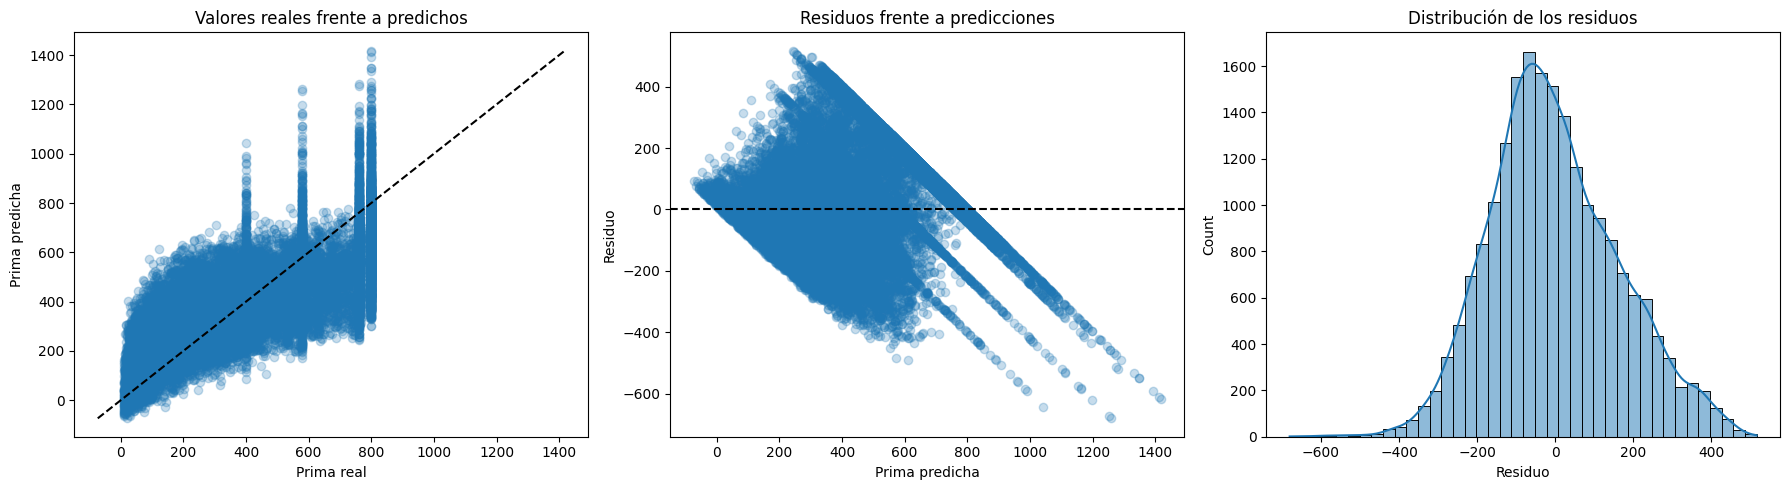

In [48]:
import statsmodels.api as sm

residuos_lineal = y_test - pred_test_lineal

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Valores reales frente a valores predichos
axes[0].scatter(y_test, pred_test_lineal, alpha=0.25)

limites = [
    min(y_test.min(), pred_test_lineal.min()),
    max(y_test.max(), pred_test_lineal.max())
]

axes[0].plot(limites, limites, "k--")
axes[0].set_xlabel("Prima real")
axes[0].set_ylabel("Prima predicha")
axes[0].set_title("Valores reales frente a predichos")

# Residuos frente a predicciones
axes[1].scatter(pred_test_lineal, residuos_lineal, alpha=0.25)
axes[1].axhline(0, color="black", linestyle="--")
axes[1].set_xlabel("Prima predicha")
axes[1].set_ylabel("Residuo")
axes[1].set_title("Residuos frente a predicciones")

# Distribución de los residuos
sns.histplot(residuos_lineal, bins=40, kde=True, ax=axes[2])
axes[2].set_xlabel("Residuo")
axes[2].set_title("Distribución de los residuos")

plt.tight_layout()
plt.show()

Visualizamos los intervalos de confianza

### Diagnostico

In [24]:
prediccion_train_scaled = modelo.predict(exog=X_train_scaled)
residuos_train_scaled = prediccion_train_scaled - y_train

C:\Users\macia\AppData\Local\Temp\ipykernel_20688\4158859051.py:5: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k--" (-> color='k'). The keyword argument will take precedence.
  axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', color = 'black', lw=2)


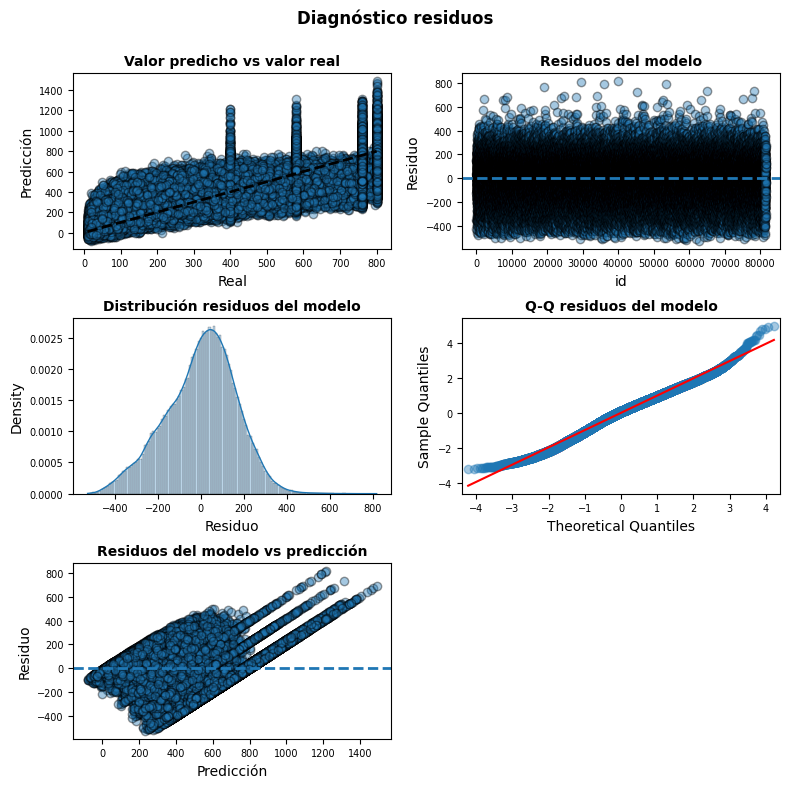

In [25]:
# Gráficos
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(8, 8))

axes[0, 0].scatter(y_train, prediccion_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 0].plot([y_train.min(), y_train.max()], [y_train.min(), y_train.max()], 'k--', color = 'black', lw=2)
axes[0, 0].set_title('Valor predicho vs valor real', fontsize = 10, fontweight = "bold")
axes[0, 0].set_xlabel('Real')
axes[0, 0].set_ylabel('Predicción')
axes[0, 0].tick_params(labelsize = 7)

axes[0, 1].scatter(list(range(len(y_train))), residuos_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[0, 1].axhline(y = 0, linestyle = '--', lw=2)
axes[0, 1].set_title('Residuos del modelo', fontsize = 10, fontweight = "bold")
axes[0, 1].set_xlabel('id')
axes[0, 1].set_ylabel('Residuo')
axes[0, 1].tick_params(labelsize = 7)

sns.histplot(
    data    = residuos_train_scaled,
    stat    = "density",
    kde     = True,
    line_kws= {'linewidth': 1},
    alpha   = 0.3,
    ax      = axes[1, 0]
)

axes[1, 0].set_title('Distribución residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 0].set_xlabel("Residuo")
axes[1, 0].tick_params(labelsize = 7)


sm.qqplot(
    residuos_train_scaled,
    fit   = True, # estandariza los residuos con su ppropia media y desviación típica
    line  = 'q',
    ax    = axes[1, 1], 
    alpha = 0.4,
    lw    = 2
)
axes[1, 1].set_title('Q-Q residuos del modelo', fontsize = 10, fontweight = "bold")
axes[1, 1].tick_params(labelsize = 7)

axes[2, 0].scatter(prediccion_train_scaled, residuos_train_scaled, edgecolors=(0, 0, 0), alpha = 0.4)
axes[2, 0].axhline(y = 0, linestyle = '--', lw=2)
axes[2, 0].set_title('Residuos del modelo vs predicción', fontsize = 10, fontweight = "bold")
axes[2, 0].set_xlabel('Predicción')
axes[2, 0].set_ylabel('Residuo')
axes[2, 0].tick_params(labelsize = 7)

# Se eliminan los axes vacíos
fig.delaxes(axes[2, 1])
fig.tight_layout() # Recoloca automáticamente los gráficos para que títulos y etiquetas no se solapen
plt.subplots_adjust(top=0.9) # Deja libre el 10% superior de la figura para el título general
fig.suptitle('Diagnóstico residuos', fontsize = 12, fontweight = "bold");


Los gráficos muestran que el modelo sigue la tendencia general de los datos, aunque existe dispersión entre los valores reales y predichos. Los residuos se distribuyen alrededor de cero, lo que indica que no hay un sesgo claro en las predicciones. La distribución de los residuos es aproximadamente normal, aunque el gráfico Q-Q muestra ligeras desviaciones en los extremos. Además, se aprecia cierta variabilidad no constante en los residuos para algunas predicciones, por lo que el ajuste es razonable, pero no perfecto.

### Test Normalidad

In [26]:
from scipy import stats

shapiro_test = stats.shapiro(residuos_train_scaled)
shapiro_test

c:\Users\macia\AppData\Local\Programs\Python\Python313\Lib\site-packages\scipy\stats\_axis_nan_policy.py:579: UserWarning: scipy.stats.shapiro: For N > 5000, computed p-value may not be accurate. Current N is 81516.
  res = hypotest_fun_out(*samples, **kwds)


ShapiroResult(statistic=np.float64(0.9927221862612725), pvalue=np.float64(3.123644373644834e-49))

El test de Shapiro-Wilk obtiene un estadístico de 0,993 y un p-valor muy próximo a 0, por lo que se rechaza la hipótesis de normalidad de los residuos. Sin embargo, debido al gran tamaño de la muestra (más de 80.000 observaciones), pequeñas desviaciones de la normalidad resultan significativas. Por ello, es recomendable complementar este resultado con el histograma y el gráfico Q-Q, que muestran una distribución aproximadamente normal con ligeras desviaciones en los extremos.

In [27]:
k2, p_value = stats.normaltest(residuos_train_scaled)
print(f"Estadítico= {k2}, p-value = {p_value}")

Estadítico= 821.6050543425627, p-value = 3.8969900560233936e-179


### Predicciones

In [28]:
predicciones = modelo.get_prediction(exog = X_train_scaled).summary_frame(alpha=0.05)
predicciones.head(4)

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
78621,318.240992,1.415800,315.466033,321.015951,-2.935305,639.417289
21210,316.086622,1.300235,313.538170,318.635073,-5.087798,637.261042
90376,371.783152,0.841786,370.133257,373.433047,50.614605,692.951699
35089,446.768226,1.130881,444.551708,448.984745,125.596269,767.940184


Los intervalos de confianza de las predicciones son relativamente estrechos para la media estimada, lo que indica que el modelo realiza estimaciones estables. Sin embargo, los intervalos de predicción para observaciones individuales son bastante más amplios, reflejando la variabilidad existente en los datos. En conjunto, el modelo permite obtener predicciones razonables de la prima, aunque existe incertidumbre significativa al estimar casos concretos.

### Error de Test

In [29]:
X_test_scaled = sm.add_constant(X_test_scaled, prepend=True)
predicciones = modelo.predict(exog = X_test_scaled)
rmse = root_mean_squared_error(y_true=y_test, y_pred=predicciones)
print(f"El error (rmse) de test es: {round(rmse, 2)}")

El error (rmse) de test es: 165.22


Como bien hemos mencionado anteriormente, el modelo obtiene un RMSE de 165,22 en el conjunto de prueba, lo que significa que las predicciones se desvían del valor real de la prima en aproximadamente 165 € de media. Este resultado indica que el modelo presenta una capacidad predictiva aceptable, aunque todavía existe un margen de error considerable en algunas predicciones.

Como existe margen de mejora, se procedera a la creación de un modelo polinomico y se procedera a compararlos

# REGRESIÓN POLINÓMICA

In [49]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.model_selection import KFold, cross_validate, learning_curve

Escalamos los datos

Se estandarizan las variables dentro del Pipeline para evitar que la validación cruzada utilice información de las particiones de validación al ajustar el escalador.

Se comparan los grados 1, 2 y 3 mediante validación cruzada. Se utiliza el RMSE medio de validación para seleccionar el grado con mejor capacidad predictiva, sin utilizar el conjunto de test en esta decisión.

In [50]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

resultados_grados = []

for grado in [1, 2, 3]:

    modelo_pol = Pipeline([
        ("escalador", StandardScaler()),
        ("polinomio", PolynomialFeatures(
            degree=grado,
            include_bias=False
        )),
        ("regresion", LinearRegression())
    ])

    scores = cross_validate(
        modelo_pol,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        },
        return_train_score=True,
        n_jobs=1
    )

    n_variables = PolynomialFeatures(
        degree=grado,
        include_bias=False
    ).fit(X_train).n_output_features_

    resultados_grados.append({
        "Grado": grado,
        "Variables_generadas": n_variables,
        "RMSE_train_CV": -scores["train_rmse"].mean(),
        "RMSE_validacion_CV": -scores["test_rmse"].mean(),
        "MAE_validacion_CV": -scores["test_mae"].mean(),
        "R2_validacion_CV": scores["test_r2"].mean()
    })

resultados_grados = pd.DataFrame(resultados_grados)

display(
    resultados_grados
    .sort_values("RMSE_validacion_CV")
    .round(3)
)

,Grado,Variables_generadas,RMSE_train_CV,RMSE_validacion_CV,MAE_validacion_CV,R2_validacion_CV
2,3,55,111.021,111.119,82.672,0.827
1,2,20,124.498,124.548,96.103,0.783
0,1,5,163.852,163.864,130.466,0.624


El grado seleccionado será el que obtenga el menor RMSE medio de validación cruzada. Se compararán también el MAE y el R² para valorar el rendimiento y se comprobará la diferencia entre los errores de entrenamiento y validación para detectar posibles indicios de sobreajuste.

Entrenamos el modelo polinómico final con el grado seleccionado mediante validación cruzada y evaluamos su rendimiento en el conjunto de test.

In [51]:
mejor_grado = int(
    resultados_grados.loc[
        resultados_grados["RMSE_validacion_CV"].idxmin(),
        "Grado"
    ]
)

print("Mejor grado seleccionado:", mejor_grado)

modelo_polinomico = Pipeline([
    ("escalador", StandardScaler()),
    ("polinomio", PolynomialFeatures(
        degree=mejor_grado,
        include_bias=False
    )),
    ("regresion", LinearRegression())
])

modelo_polinomico.fit(X_train, y_train)

pred_train_polinomico = modelo_polinomico.predict(X_train)
pred_test_polinomico = modelo_polinomico.predict(X_test)

metricas_polinomico = pd.DataFrame({
    "Entrenamiento": evaluar_modelo(y_train, pred_train_polinomico),
    "Test": evaluar_modelo(y_test, pred_test_polinomico)
}).T

display(metricas_polinomico.round(3))

Mejor grado seleccionado: 3


,MAE,RMSE,R2
Entrenamiento,82.602,111.031,0.827
Test,83.376,112.035,0.824


### CURVAS DE APRENDIZAJE

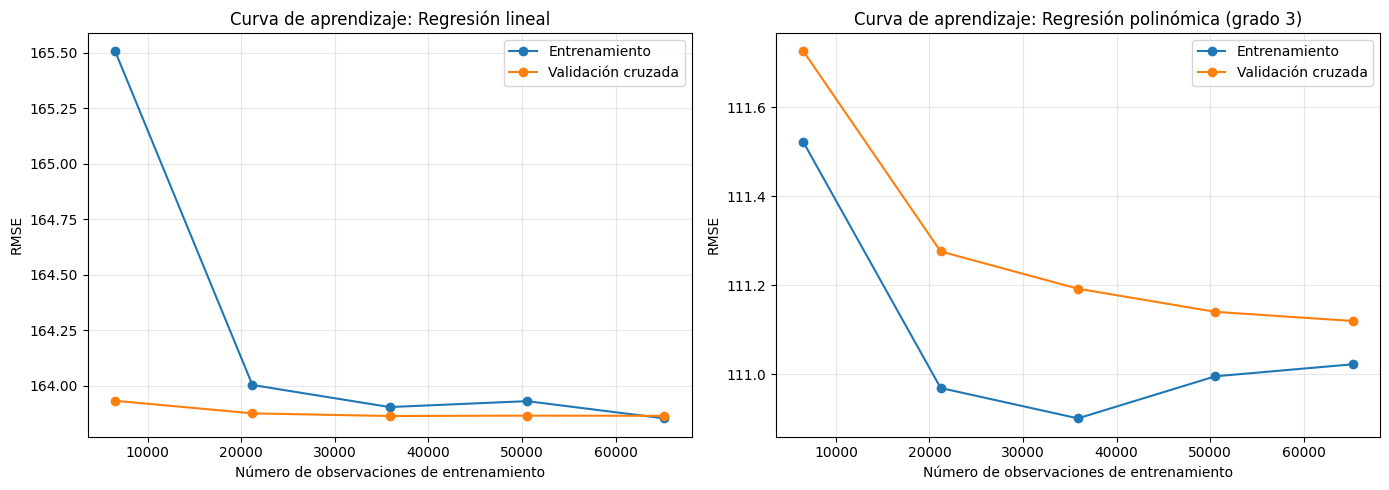

In [52]:
modelos_curvas = [
    ("Regresión lineal", modelo_lineal),
    (f"Regresión polinómica (grado {mejor_grado})", modelo_polinomico)
]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (nombre, estimador) in zip(axes, modelos_curvas):

    tamanos, errores_train, errores_validacion = learning_curve(
        estimador,
        X_train,
        y_train,
        train_sizes=np.linspace(0.1, 1.0, 5),
        cv=KFold(n_splits=5, shuffle=True, random_state=42),
        scoring="neg_root_mean_squared_error",
        n_jobs=1
    )

    ax.plot(
        tamanos,
        -errores_train.mean(axis=1),
        marker="o",
        label="Entrenamiento"
    )

    ax.plot(
        tamanos,
        -errores_validacion.mean(axis=1),
        marker="o",
        label="Validación cruzada"
    )

    ax.set_title(f"Curva de aprendizaje: {nombre}")
    ax.set_xlabel("Número de observaciones de entrenamiento")
    ax.set_ylabel("RMSE")
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

,MAE,RMSE,R2
Regresión lineal,131.736,165.218,0.617
Regresión polinómica (grado 3),83.376,112.035,0.824


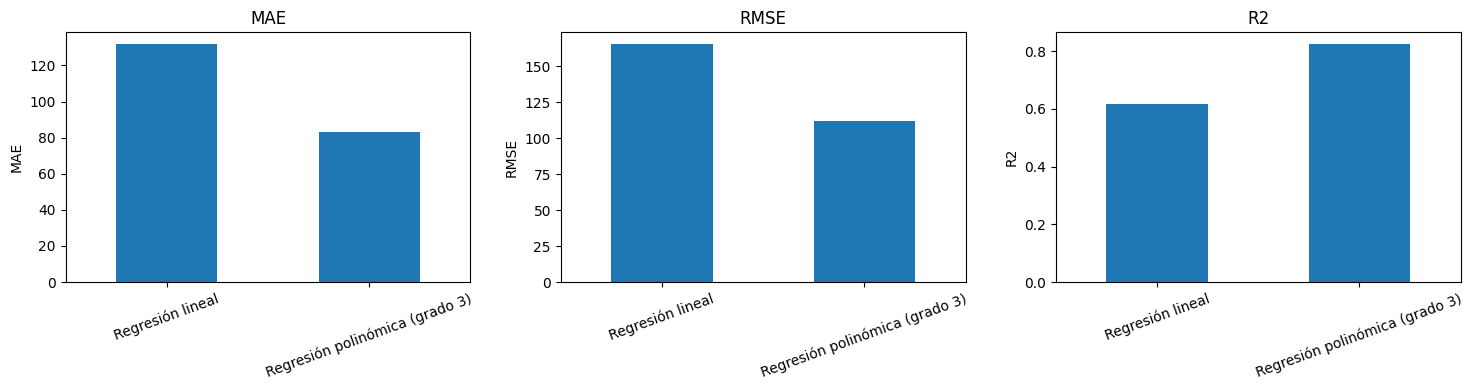

In [53]:
comparacion = pd.DataFrame({
    "Regresión lineal": evaluar_modelo(y_test, pred_test_lineal),
    f"Regresión polinómica (grado {mejor_grado})": evaluar_modelo(
        y_test,
        pred_test_polinomico
    )
}).T

display(comparacion.round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, metrica in zip(axes, ["MAE", "RMSE", "R2"]):

    comparacion[metrica].plot(
        kind="bar",
        ax=ax,
        legend=False
    )

    ax.set_title(metrica)
    ax.set_ylabel(metrica)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

### REGULARIZACIÓN

In [ ]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.model_selection import GridSearchCV, KFold

cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Ridge
modelo_ridge = Pipeline([
    ("escalador", StandardScaler()),
    ("polinomio", PolynomialFeatures(
        degree=mejor_grado, include_bias=False
    )),
    ("regresion", Ridge())
])

busqueda_ridge = GridSearchCV(
    modelo_ridge,
    {"regresion__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1
)

busqueda_ridge.fit(X_train, y_train)


# Lasso
modelo_lasso = Pipeline([
    ("escalador", StandardScaler()),
    ("polinomio", PolynomialFeatures(
        degree=mejor_grado, include_bias=False
    )),
    ("regresion", Lasso(max_iter=10000))
])

busqueda_lasso = GridSearchCV(
    modelo_lasso,
    {"regresion__alpha": [0.01, 0.1, 1, 10, 100]},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1
)

busqueda_lasso.fit(X_train, y_train)


# Elastic Net
modelo_elastic = Pipeline([
    ("escalador", StandardScaler()),
    ("polinomio", PolynomialFeatures(
        degree=mejor_grado, include_bias=False
    )),
    ("regresion", ElasticNet(max_iter=10000))
])

busqueda_elastic = GridSearchCV(
    modelo_elastic,
    {
        "regresion__alpha": [0.01, 0.1, 1, 10, 100],
        "regresion__l1_ratio": [0.2, 0.5, 0.8]
    },
    scoring="neg_root_mean_squared_error",
    cv=cv,
    n_jobs=1
)

busqueda_elastic.fit(X_train, y_train)

In [ ]:
resultados_cv = pd.DataFrame({
    "Modelo": ["Ridge", "Lasso", "Elastic Net"],
    "Mejores parámetros": [
        busqueda_ridge.best_params_,
        busqueda_lasso.best_params_,
        busqueda_elastic.best_params_
    ],
    "RMSE validación cruzada": [
        -busqueda_ridge.best_score_,
        -busqueda_lasso.best_score_,
        -busqueda_elastic.best_score_
    ]
})

display(resultados_cv.round(3))

Grado polinómico: 3
Mejor alpha: 1
RMSE medio de validación cruzada: 111.119


In [ ]:
pred_ridge = busqueda_ridge.best_estimator_.predict(X_test)
pred_lasso = busqueda_lasso.best_estimator_.predict(X_test)
pred_elastic = busqueda_elastic.best_estimator_.predict(X_test)

comparacion_regularizacion = pd.DataFrame({
    "Ridge": evaluar_modelo(y_test, pred_ridge),
    "Lasso": evaluar_modelo(y_test, pred_lasso),
    "Elastic Net": evaluar_modelo(y_test, pred_elastic)
}).T

display(comparacion_regularizacion.round(3))